In [1]:
import os, sys, json, shutil, glob
from pathlib import Path
REPO = Path("/kaggle/working/repo")
if not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval
sys.path.insert(0, str(REPO / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import vdet, infer
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working"); RUNS = OUT / "runs"; RUNS.mkdir(exist_ok=True)
RESULT_DIRS = [REPO / "results", RUNS]
for cfg_file in glob.glob("/kaggle/input/**/runs/*/config.json", recursive=True):
    src = Path(cfg_file).parent
    if not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name, ignore=shutil.ignore_patterns("*.pt", "*.pth")); print("restored", src.name)

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 249, done.
remote: Counting objects: 100% (249/249), done.
remote: Compressing objects: 100% (238/238), done.
remote: Total 249 (delta 98), reused 18 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (249/249), 45.03 MiB | 23.96 MiB/s, done.
Resolving deltas: 100% (98/98), done.
restored frcnn_e0_base
restored frcnn_e1_proposals
restored frcnn_e2_giou
restored frcnn_e3_roi_sampling
restored frcnn_e4_cosine
restored final_all_clips
restored final_b1_step5
restored final_b2_fullaug
restored final_b3_24ep
restored yolo_y0_base
restored yolo_y1_p2
restored yolo_y2_imgsz1024
restored yolo_y2_imgsz1536
restored yolo_y3_tal13


In [2]:
# RetinaNet results are stored flat in results/retinanet/<run>_<file>; arrange them as one folder per run
flat = REPO / "results" / "retinanet"
for f in sorted(flat.glob("retina_*")):
    for suffix in ("_config.json", "_history.json", "_metrics.json", "_val_preds.csv.gz"):
        if f.name.endswith(suffix):
            run = f.name[: -len(suffix)]
            (RUNS / run).mkdir(exist_ok=True)
            shutil.copy(f, RUNS / run / suffix[1:])
print(sorted(p.name for p in RUNS.glob("retina_*")))

['retina_r0_base', 'retina_r1_anchors', 'retina_r2_iou', 'retina_r3_focal', 'retina_r4_l1']


In [3]:
imgs, anns = vdet.load_all(ROOT)
folds = vdet.make_folds(imgs, vdet.PROTOCOL["n_folds"])
_, val_frames = vdet.protocol_frames(imgs, folds, vdet.PROTOCOL)
print(len(val_frames), "holdout frames")

545 holdout frames


,family,AP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_img
run,,,,,,,,
frcnn_e1_proposals,Two-stage,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,114.2782
final_b2_fullaug,Anchor-free + augmentation,0.2366,0.4288,0.2264,0.1150,0.1773,0.3953,17.5034
retina_r0_base,One-stage anchor-based,0.2303,0.4217,0.2190,0.0759,0.1743,0.4362,50.7341
yolo_y2_imgsz1536,Anchor-free,0.2097,0.4052,0.1939,0.0926,0.1766,0.3248,30.5283
detr_d2_cost_giou,Query-based,0.0563,0.1010,0.0561,0.0310,0.0408,0.1146,87.2984


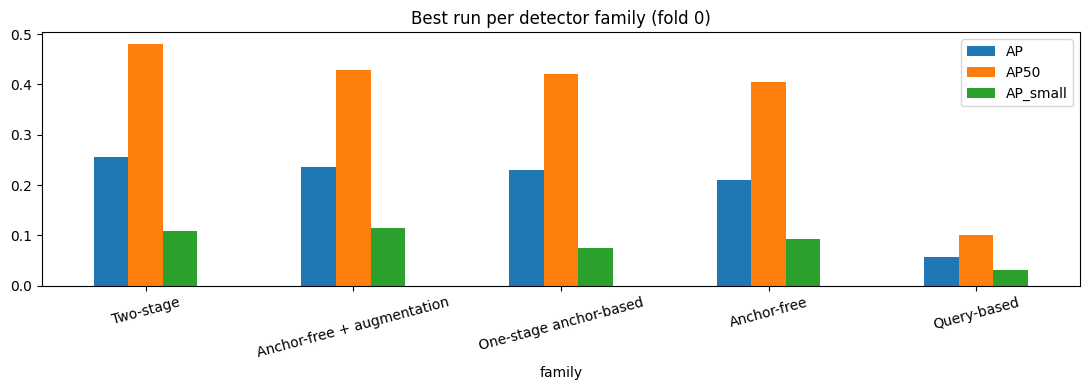

In [4]:
# Best run of each detector family on the same holdout (summary comparison of all models)
allres = vdet.collect_results(RESULT_DIRS)
fam = {"frcnn": "Two-stage", "retina": "One-stage anchor-based", "yolo": "Anchor-free",
       "final": "Anchor-free + augmentation", "detr": "Query-based"}
allres["family"] = allres.index.str.split("_").str[0].map(fam)
allres = allres.drop(index=[r for r in allres.index if r == "final_all_clips"], errors="ignore")
best = allres.loc[allres.groupby("family").AP.idxmax()].sort_values("AP", ascending=False)
cols = ["family", "AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_img"]
display(best[cols].round(4))
best.set_index("family")[["AP", "AP50", "AP_small"]].plot.bar(figsize=(11, 4), rot=15, title="Best run per detector family (fold 0)")
plt.tight_layout(); plt.savefig(OUT / "summary_all_models.png", dpi=120); plt.show()

In [5]:
# Does adding RetinaNet / RT-DETR to the best ensemble help on the holdout?
def preds(run):
    f = next((Path(d) / run / "val_preds.csv.gz" for d in RESULT_DIRS if (Path(d) / run / "val_preds.csv.gz").exists()), None)
    return pd.read_csv(f) if f is not None else None
base = {"frcnn_e1_proposals": preds("frcnn_e1_proposals"), "final_b2_fullaug": preds("final_b2_fullaug")}
extra = {r: preds(r) for r in best.index if r not in base}
print("validation predictions found for:", list(base) + [r for r, p in extra.items() if p is not None])
rows = {"WBF FRCNN + B2": infer.wbf(list(base.values()), iou_thr=0.55)}
for r, p in extra.items():
    if p is not None:
        rows[f"WBF FRCNN + B2 + {r}"] = infer.wbf(list(base.values()) + [p], iou_thr=0.55)
tab = pd.DataFrame({k: vdet.coco_evaluate(val_frames, anns, v, per_class=False) for k, v in rows.items()}).T
display(tab[["AP", "AP50", "AP_small", "AP_medium"]].round(4))

validation predictions found for: ['frcnn_e1_proposals', 'final_b2_fullaug', 'retina_r0_base', 'yolo_y2_imgsz1536']


,AP,AP50,AP_small,AP_medium
WBF FRCNN + B2,0.2820,0.5139,0.1282,0.2241
WBF FRCNN + B2 + retina_r0_base,0.2929,0.5328,0.1284,0.2344
WBF FRCNN + B2 + yolo_y2_imgsz1536,0.2829,0.5193,0.1305,0.2350


In [6]:
from pathlib import Path

for p in sorted(Path("/kaggle/input").rglob("*")):
    if p.is_file() and (
        "submission" in p.name.lower()
        or "test_preds" in p.name.lower()
    ):
        print(p)

/kaggle/input/datasets/tttanyamoroz/retina-sub/submission_retina_r0_base.csv
/kaggle/input/notebooks/dariaisme/02-faster-r-cnn/submission_frcnn_e1_proposals.csv
/kaggle/input/notebooks/dariaisme/02-faster-r-cnn/test_preds_frcnn_e1_proposals.csv.gz
/kaggle/input/notebooks/dariaisme/06-final/submission_b2.csv
/kaggle/input/notebooks/dariaisme/06-final/submission_final.csv
/kaggle/input/notebooks/dariaisme/06-final/submission_final_wbf.csv
/kaggle/input/notebooks/dariaisme/06-final/submission_wbf_b2_frcnn_11.csv
/kaggle/input/notebooks/dariaisme/06-final/submission_wbf_b2_frcnn_12.csv
/kaggle/input/notebooks/dariaisme/06-final/test_preds_final.csv.gz
/kaggle/input/notebooks/dariaisme/06-final/test_preds_final_b2_fullaug.csv.gz


In [7]:
from pathlib import Path
import pandas as pd

# Готові прогнози трьох моделей
frcnn_path = Path(
    "/kaggle/input/notebooks/dariaisme/02-faster-r-cnn/"
    "test_preds_frcnn_e1_proposals.csv.gz"
)

b2_path = Path(
    "/kaggle/input/notebooks/dariaisme/06-final/"
    "test_preds_final_b2_fullaug.csv.gz"
)

retina_path = Path(
    "/kaggle/input/datasets/tttanyamoroz/retina-sub/"
    "submission_retina_r0_base.csv"
)

# Перевіряємо файли
for p in [frcnn_path, b2_path, retina_path]:
    assert p.exists(), f"File not found: {p}"
    print("Found:", p.name)

# Завантажуємо прогнози
frcnn = pd.read_csv(frcnn_path)
b2 = pd.read_csv(b2_path)
retina = vdet.parse_submission(retina_path)

# Приводимо до однакового формату
parts = [
    df.rename(columns={"image_id": "key"})
    for df in [frcnn, b2, retina]
]

# Weighted Boxes Fusion
fused = infer.wbf(parts, iou_thr=0.55)
fused = fused.rename(columns={"key": "image_id"})

# Створюємо submission
output_path = OUT / "submission_wbf_b2_frcnn_retina.csv"

vdet.write_submission(
    fused,
    ROOT / "test_images.csv",
    output_path
)

print("FINAL SUBMISSION:", output_path)

Found: test_preds_frcnn_e1_proposals.csv.gz
Found: test_preds_final_b2_fullaug.csv.gz
Found: submission_retina_r0_base.csv
submission OK: 3811 rows, 3811 non-empty
FINAL SUBMISSION: /kaggle/working/submission_wbf_b2_frcnn_retina.csv
